# 02 — Preprocessing and data augmentation

This notebook prepares the data for the model. It:

1. loads the train / validation / test split created by notebook 01;
2. defines the image loading and preprocessing functions;
3. defines the augmentation functions (blur, horizontal flip, Gaussian noise);
4. visualizes original and augmented images;
5. balances the training set by oversampling minority classes and saves
   `data/processed/train_balanced.json`;
6. builds a `tf.data` pipeline with on-the-fly augmentation.

> **How to read this notebook:** every code cell is preceded by a short
> summary that explains what the step does and how to interpret its output.


## 1. Imports and paths

Imports the libraries and defines the paths and constants shared by the
notebook (image size 224x224, batch size 32, seed 42).

**How to read the output:** check that the printed TensorFlow version and
`splits.json` path are correct. If the file is missing, run notebook 01 first.

In [1]:
from pathlib import Path
from collections import Counter
import json
import random

import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd()
if ROOT_DIR.name == "notebooks":
    ROOT_DIR = ROOT_DIR.parent

PROCESSED_DIR = ROOT_DIR / "data" / "processed"
SPLITS_PATH = PROCESSED_DIR / "splits.json"
BALANCED_PATH = PROCESSED_DIR / "train_balanced.json"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow :", tf.__version__)
print("Splits file:", SPLITS_PATH)


I0000 00:00:1793320168.859030   11682 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793320168.867461   11682 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793320170.083583   11682 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793320172.056844   11682 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:0

TensorFlow : 2.21.0
Splits file: /home/fangyuan/Projects/Diagnostic-des-tumeurs/data/processed/splits.json


## 2. Load the train / validation / test split

Reads `data/processed/splits.json` created by notebook 01 and converts the
stored relative paths into absolute paths.

**How to read the output:** the class list and the three dataset sizes. They
must match the last cell of notebook 01.

In [2]:
if not SPLITS_PATH.exists():
    raise FileNotFoundError(
        f"{SPLITS_PATH} not found. Run 01_data_overview.ipynb first."
    )

with open(SPLITS_PATH) as f:
    splits = json.load(f)

classes = splits["classes"]
class_to_id = splits["class_to_id"]
id_to_class = {int(k): v for k, v in splits["id_to_class"].items()}
IMG_SIZE = tuple(splits.get("img_size", IMG_SIZE))

def absolute(path: str) -> str:
    return str((ROOT_DIR / path).resolve())

train_paths = [absolute(p) for p in splits["train"]["paths"]]
train_labels = splits["train"]["labels"]
val_paths = [absolute(p) for p in splits["val"]["paths"]]
val_labels = splits["val"]["labels"]
test_paths = [absolute(p) for p in splits["test"]["paths"]]
test_labels = splits["test"]["labels"]

print("Classes:", classes)
print("Train  :", len(train_paths))
print("Val    :", len(val_paths))
print("Test   :", len(test_paths))


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Train  : 4916
Val    : 1053
Test   : 1054


## 3. Define the image loader

`load_image` reads one file, converts BGR to RGB (OpenCV loads BGR, the model
expects RGB), resizes it to 224x224 and returns a `float32` array in the
`[0, 255]` range.

**How to read the output:** this cell prints nothing; it only defines the
function used by the `tf.data` pipeline and the visualizations. Pixel
rescaling to `[-1, 1]` is done inside the model in notebook 03.

In [3]:
def load_image(path, label=None):
    """Load one image as an RGB float32 array in the [0, 255] range."""
    if isinstance(path, tf.Tensor):
        path = path.numpy().decode("utf-8")

    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(f"Image not found or cannot be read: {path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, IMG_SIZE)
    image = image.astype(np.float32)

    if label is None:
        return image
    return image, label


## 4. Define the augmentations

Three light transformations are available: Gaussian blur, horizontal flip and
Gaussian noise. `augment_data` picks one at random for each image.

**How to read the output:** no output yet. Augmentation stays in memory: the
images are transformed as NumPy arrays while the batch is built, and no
augmented file is written to disk.

In [4]:
def apply_blur(image, label):
    return cv2.GaussianBlur(image, (5, 5), 0), label


def apply_flip(image, label):
    return cv2.flip(image, 1), label


def apply_noise(image, label):
    noise = np.random.normal(loc=0, scale=10, size=image.shape)
    noisy = np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.float32)
    return noisy, label


def augment_data(image, label):
    """Apply one random augmentation to an image."""
    transformations = [apply_blur, apply_flip, apply_noise]
    return random.choice(transformations)(image, label)


## 5. Visualize the augmentations

Loads one training image and shows the original next to the three
augmentations.

**How to read the output:** all four panels must still look like the same
medical image. If an augmentation destroys the anatomy (for example an
excessive blur or noise level), reduce it before training.

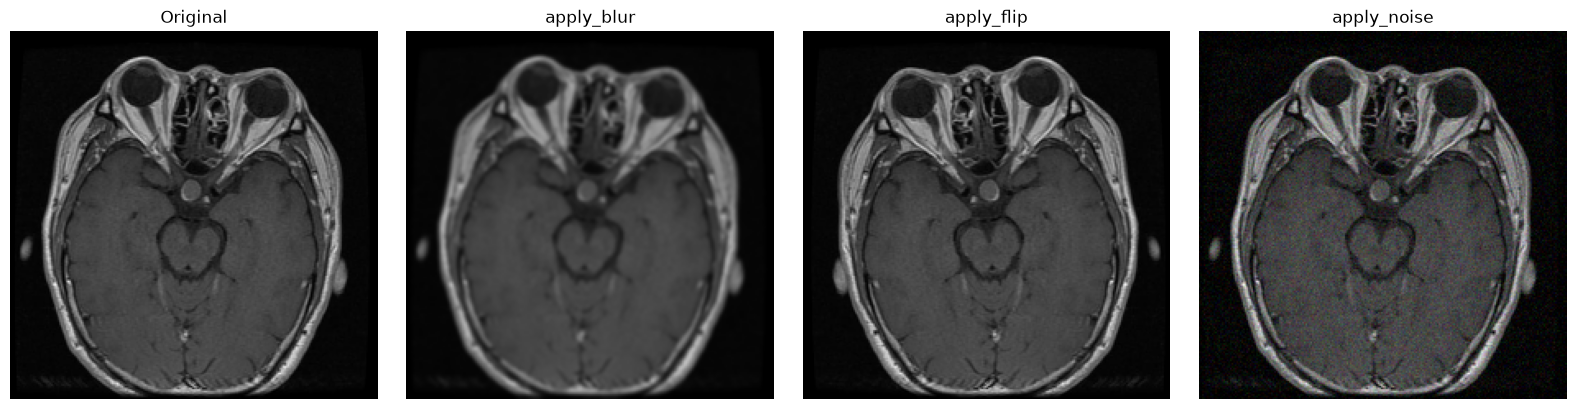

In [5]:
random.seed(SEED)
sample_path = random.choice(train_paths)
original = load_image(sample_path)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes[0].imshow(original.astype(np.uint8))
axes[0].set_title("Original")
axes[0].axis("off")

for ax, transform in zip(axes[1:], [apply_blur, apply_flip, apply_noise]):
    augmented, _ = transform(original, 0)
    ax.imshow(augmented.astype(np.uint8))
    ax.set_title(transform.__name__)
    ax.axis("off")

plt.tight_layout()
plt.show()


## 6. Balance the training set by oversampling

Counts the training images per class and duplicates random paths of the
minority classes until every class has as many examples as the largest one.

**How to read the output:** compare `Original counts` with `Balanced counts`:
every class should now have the same number, and `Total balanced` is larger
than the original training size. Only paths are duplicated; the pixels are
re-read and augmented at training time, so the model still sees variations.

In [6]:
# Oversample minority classes so every class has the same number of
# training examples. Augmentation is applied later, on the fly.
train_counts = Counter(train_labels)
target_count = max(train_counts.values())

balanced_paths, balanced_labels = [], []
random.seed(SEED)

for class_id in range(len(classes)):
    class_paths = [p for p, y in zip(train_paths, train_labels) if y == class_id]

    balanced_paths.extend(class_paths)
    balanced_labels.extend([class_id] * len(class_paths))

    missing = target_count - len(class_paths)
    if missing > 0:
        balanced_paths.extend(random.choices(class_paths, k=missing))
        balanced_labels.extend([class_id] * missing)

print("Original counts:", {id_to_class[k]: v for k, v in sorted(train_counts.items())})
print("Balanced counts:", {id_to_class[k]: v for k, v in sorted(Counter(balanced_labels).items())})
print("Total balanced :", len(balanced_paths))


Original counts: {'glioma': 1135, 'meningioma': 1151, 'notumor': 1400, 'pituitary': 1230}
Balanced counts: {'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400}
Total balanced : 5600


## 7. Save the balanced manifest

Writes the oversampled paths and labels to
`data/processed/train_balanced.json`.

**How to read the output:** the saved path is printed. Notebook 03 reads this
manifest for training, while notebook 04 goes back to the original split and
uses class weights, which avoids over-fitting to duplicated images.

In [7]:
balanced = {
    "classes": classes,
    "class_to_id": class_to_id,
    "id_to_class": {str(k): v for k, v in id_to_class.items()},
    "img_size": list(IMG_SIZE),
    "seed": SEED,
    "paths": [
        Path(p).relative_to(ROOT_DIR).as_posix() for p in balanced_paths
    ],
    "labels": [int(y) for y in balanced_labels],
}

with open(BALANCED_PATH, "w") as f:
    json.dump(balanced, f, indent=2)

print("Saved balanced manifest:", BALANCED_PATH)


Saved balanced manifest: /home/fangyuan/Projects/Diagnostic-des-tumeurs/data/processed/train_balanced.json


## 8. Build the `tf.data` pipeline

Creates batched, prefetched datasets. The training set is shuffled and
augmented on the fly; validation is neither shuffled nor augmented.

**How to read the output:** the dataset summary and one batch shape
`(32, 224, 224, 3)` with pixels between `0` and `255`. This pipeline is the
template reused by notebooks 03 and 04.

In [8]:
def _decode_path(value):
    if isinstance(value, tf.Tensor):
        value = value.numpy()
    if hasattr(value, "decode"):
        return value.decode("utf-8")
    return str(value)


def load_image_tf(path, label):
    def _load(path_tensor):
        return load_image(_decode_path(path_tensor))

    image = tf.numpy_function(_load, [path], tf.float32)
    image.set_shape((IMG_SIZE[1], IMG_SIZE[0], 3))
    return image, label


def augment_image_tf(image, label):
    def _augment(image_np, label_np):
        augmented, _ = augment_data(image_np, label_np)
        return augmented.astype(np.float32)

    image = tf.numpy_function(_augment, [image, label], tf.float32)
    image.set_shape((IMG_SIZE[1], IMG_SIZE[0], 3))
    return image, label


def make_dataset(paths, labels, training=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(load_image_tf, num_parallel_calls=AUTOTUNE)

    if augment:
        ds = ds.map(augment_image_tf, num_parallel_calls=AUTOTUNE)

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_dataset(balanced_paths, balanced_labels, training=True, augment=True)
val_ds = make_dataset(val_paths, val_labels, training=False, augment=False)

print(train_ds)
for images, labels in train_ds.take(1):
    print(
        "Batch:",
        images.shape,
        labels.shape,
        "| pixel range:",
        float(images.numpy().min()),
        float(images.numpy().max()),
    )


<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>


E0000 00:00:1793320174.912335   11682 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Batch: (32, 224, 224, 3) (32,) | pixel range: 0.0 255.0


## 9. Inspect a real training batch

Takes one batch from the training pipeline and displays the first eight
images with their class names.

**How to read the output:** the images should look correctly oriented (not
flipped vertically, not color-swapped) and their titles should match their
content. This is the last check before the images reach the model.

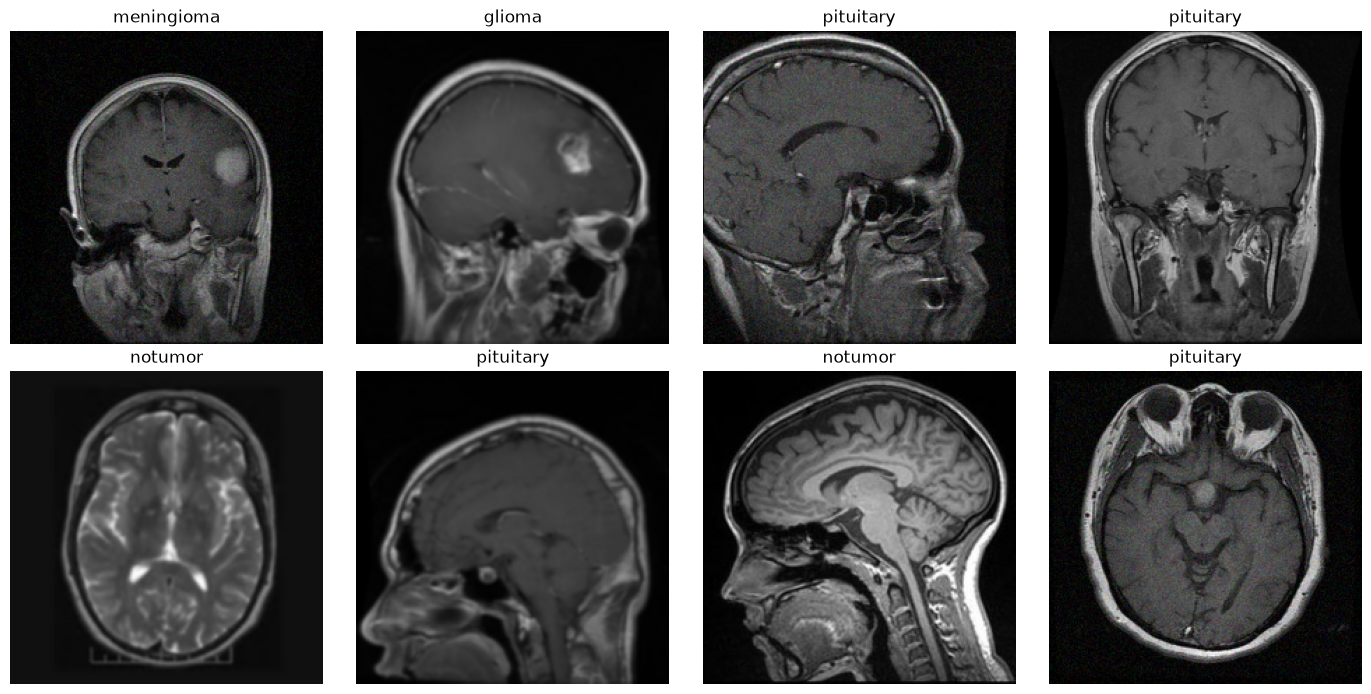

In [9]:
images, labels = next(iter(train_ds))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, image, label in zip(axes.ravel(), images[:8], labels[:8]):
    ax.imshow(image.numpy().astype(np.uint8))
    ax.set_title(id_to_class[int(label)])
    ax.axis("off")

plt.tight_layout()
plt.show()


## Next step

Open **`03_feature_extraction.ipynb`**. It uses the balanced manifest and the
split to extract InceptionV3 features and train the classification head.
